# 01. Análise exploratória da cesta básica
**Integrante 1.** Este notebook lê a base já limpa (`src/limpeza.py`) e responde: o que os dados mostram?
Rode as células de cima para baixo. Onde estiver **ESCREVA AQUI**, a interpretação é sua.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

limpa = pd.read_csv("../data/processed/cesta_limpa.csv", parse_dates=["mes", "data_coleta"])
mensal = pd.read_csv("../data/processed/cesta_mensal.csv", parse_dates=["mes"])
print(limpa.shape, mensal.shape)
limpa.head()

Matplotlib is building the font cache; this may take a moment.


(44491, 8) (780, 5)


,mes,data_coleta,estab,produto,marca,preco,quantidade,ppk
0,2022-09-01,2022-09-23,SUP_33,Carne Bovina Coxão Mole,NaN,54.20,1.0,54.20
1,2022-09-01,2022-09-12,SUP_15,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
2,2022-09-01,2022-09-21,SUP_09,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
3,2022-09-01,2022-09-23,SUP_12,Carne Bovina Coxão Mole,NaN,51.99,1.0,51.99
4,2022-09-01,2022-09-12,SUP_20,Carne Bovina Coxão Mole,NaN,51.90,1.0,51.90


## 1. Visão geral da base

In [2]:
print("Período:", limpa["mes"].min().date(), "até", limpa["mes"].max().date())
print("Produtos:", limpa["produto"].nunique(), "| Estabelecimentos:", limpa["estab"].nunique())
print("Valores ausentes por coluna:")
print(limpa.isna().sum())

Período: 2022-09-01 até 2026-08-01
Produtos: 20 | Estabelecimentos: 51
Valores ausentes por coluna:
mes               0
data_coleta    9564
estab             0
produto           0
marca          9170
preco             0
quantidade        0
ppk               0
dtype: int64


### Cobertura: quantos meses de dados cada produto tem?
Produtos com poucos meses não servem para sazonalidade nem previsão.

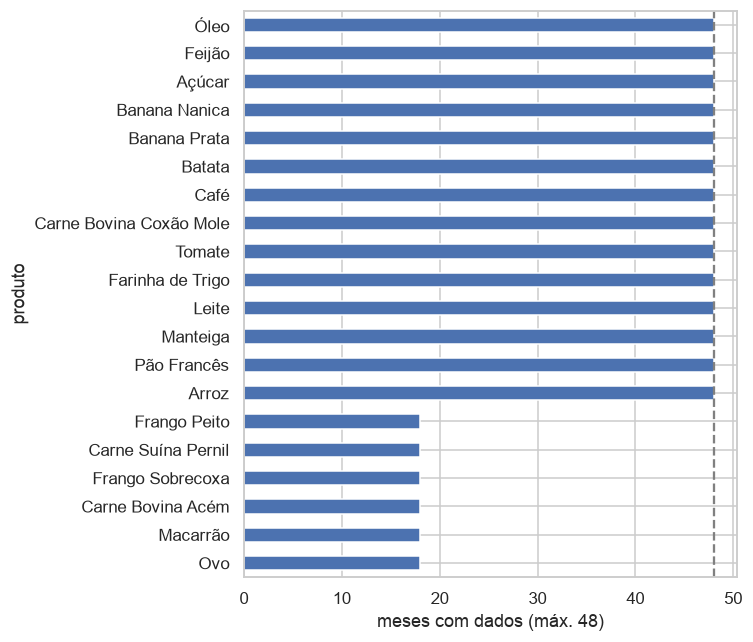

14 produtos com os 48 meses: ['Arroz', 'Pão Francês', 'Manteiga', 'Leite', 'Farinha de Trigo', 'Tomate', 'Carne Bovina Coxão Mole', 'Café', 'Batata', 'Banana Prata', 'Banana Nanica', 'Açúcar', 'Feijão', 'Óleo']


In [3]:
cobertura = mensal.groupby("produto")["mes"].nunique().sort_values()
ax = cobertura.plot.barh(figsize=(7, 6), color="#4C72B0")
ax.axvline(48, color="gray", ls="--"); ax.set_xlabel("meses com dados (máx. 48)")
plt.tight_layout(); plt.savefig(FIG / "01_cobertura_produtos.png"); plt.show()

completos = cobertura[cobertura == 48].index.tolist()
print(len(completos), "produtos com os 48 meses:", completos)

**ESCREVA AQUI:** quais produtos têm série curta e por que isso é um problema para as outras partes do projeto?

## 2. Estatísticas descritivas por produto
PPK = preço por kg (ou unidade). `cv` é o desvio padrão dividido pela média, em %: mostra quanto o preço oscila em termos relativos e permite comparar produtos de preços muito diferentes.

In [4]:
est = (limpa.groupby("produto")["ppk"]
       .agg(media="mean", mediana="median", desvio="std", minimo="min", maximo="max", n="size")
       .round(2))
est["cv_%"] = (est["desvio"] / est["media"] * 100).round(1)
est = est.sort_values("cv_%", ascending=False)
est.to_csv("../data/processed/estatisticas_descritivas.csv")
est

,media,mediana,desvio,minimo,maximo,n,cv_%
produto,,,,,,,
Batata,6.52,5.99,2.63,1.49,15.99,1283,40.3
Macarrão,8.29,7.99,3.04,2.29,21.98,1081,36.7
Café,49.10,43.98,16.15,13.78,97.98,5171,32.9
Tomate,8.97,8.99,2.91,2.95,18.99,1288,32.4
Banana Nanica,6.57,6.72,1.99,1.95,18.99,1176,30.3
Carne Suína Pernil,22.26,21.70,5.61,5.29,43.99,431,25.2
Frango Peito,23.53,22.90,5.85,8.79,49.99,436,24.9
Banana Prata,10.57,10.00,2.47,2.99,19.99,1171,23.4
Ovo,0.94,0.92,0.22,0.42,1.67,451,23.4


**ESCREVA AQUI:** quais produtos oscilam mais (cv alto)? Média e mediana são parecidas? Se não, o que isso indica?

## 3. Evolução do preço no tempo (mediana mensal)

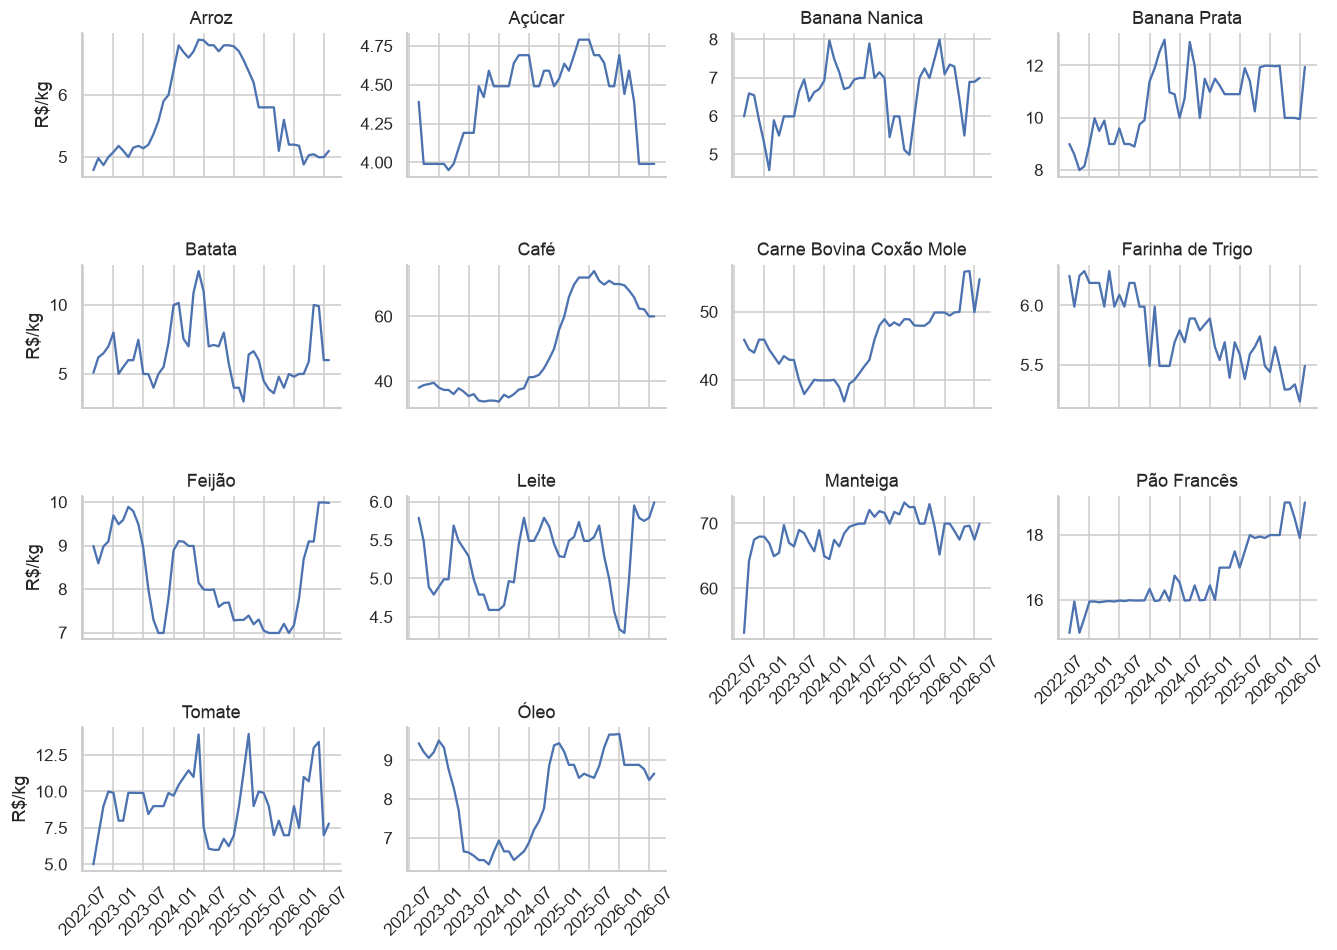

In [5]:
base = mensal[mensal["produto"].isin(completos)]
g = sns.FacetGrid(base, col="produto", col_wrap=4, sharey=False, height=2.2, aspect=1.4)
g.map_dataframe(sns.lineplot, x="mes", y="ppk_mediana", color="#4C72B0")
g.set_titles("{col_name}"); g.set_axis_labels("", "R$/kg")
for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); g.savefig(FIG / "02_evolucao_precos.png"); plt.show()

**ESCREVA AQUI:** quais produtos sobem de forma clara? Algum cai? Algum tem picos repentinos?

## 4. Variação total: primeiro vs último trimestre

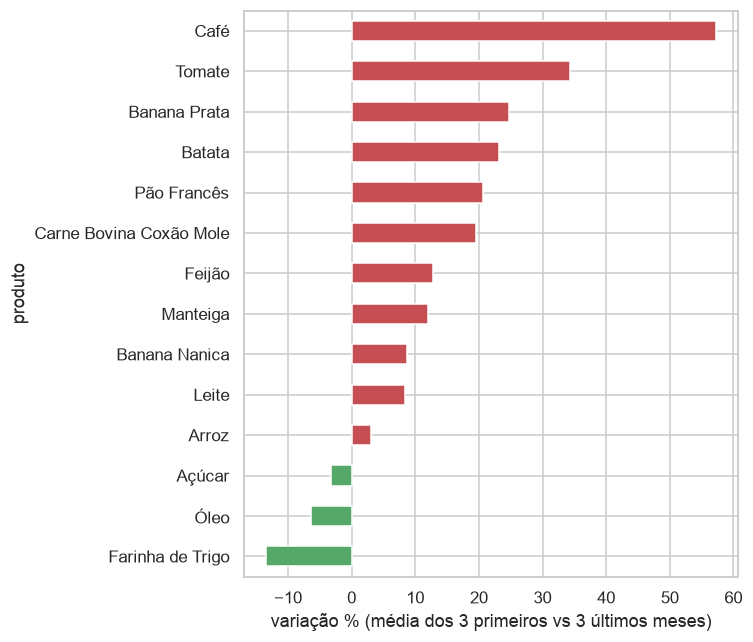

produto
Farinha de Trigo          -13.4
Óleo                       -6.5
Açúcar                     -3.2
Arroz                       3.1
Leite                       8.4
Banana Nanica               8.6
Manteiga                   12.0
Feijão                     12.8
Carne Bovina Coxão Mole    19.6
Pão Francês                20.6
Batata                     23.2
Banana Prata               24.7
Tomate                     34.4
Café                       57.2
dtype: float64

In [6]:
piv = base.pivot(index="mes", columns="produto", values="ppk_mediana")
ini = piv.iloc[:3].mean(); fim = piv.iloc[-3:].mean()
var = ((fim / ini - 1) * 100).sort_values()

ax = var.plot.barh(figsize=(7, 6), color=["#C44E52" if v > 0 else "#55A868" for v in var])
ax.set_xlabel("variação % (média dos 3 primeiros vs 3 últimos meses)")
plt.tight_layout(); plt.savefig(FIG / "03_variacao_total.png"); plt.show()
var.round(1)

**ESCREVA AQUI:** quais produtos mais encareceram? Isso bate com o que você vê no dia a dia?

## 5. Distribuição dos preços (boxplot, escala log)

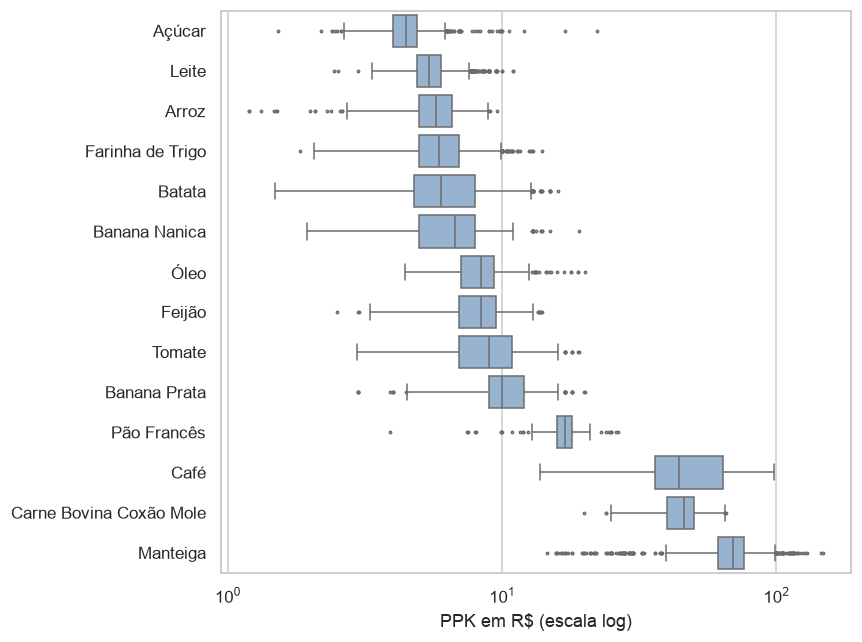

In [7]:
dados = limpa[limpa["produto"].isin(completos)]
ordem = dados.groupby("produto")["ppk"].median().sort_values().index
plt.figure(figsize=(8, 6))
sns.boxplot(data=dados, y="produto", x="ppk", order=ordem, fliersize=1.5, color="#8FB3D9")
plt.xscale("log"); plt.xlabel("PPK em R$ (escala log)"); plt.ylabel("")
plt.tight_layout(); plt.savefig(FIG / "04_boxplot_produtos.png"); plt.show()

**ESCREVA AQUI:** o que os pontos fora da caixa significam? Ainda sobraram outliers depois da limpeza?

## 6. Qualidade da coleta: quantas observações por mês?

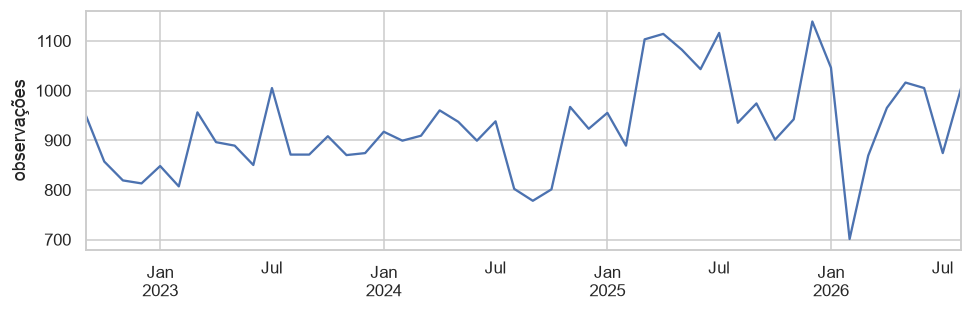

mín: 701 | máx: 1139 | mediana: 913


In [8]:
n_mes = limpa.groupby("mes").size()
ax = n_mes.plot(figsize=(9, 3), color="#4C72B0")
ax.set_ylabel("observações"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "05_coletas_por_mes.png"); plt.show()
print("mín:", n_mes.min(), "| máx:", n_mes.max(), "| mediana:", int(n_mes.median()))

**ESCREVA AQUI:** o número de coletas é estável? Meses com menos coletas deixam a mediana menos confiável?

## 7. Conclusão inicial (ESCREVA AQUI)
Em 5 a 8 linhas: o que a base permite responder, o que não permite e o que o grupo precisa decidir antes das próximas etapas.